# 0) Import packages

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from statsmodels.formula.api import ols

# 1) Load in data 

### Creating cut offs for time to remove outliers, reading in data with correct data types, and remove DNF races

In [2]:
#cut offs to remove races with these times or slower
#Change these cutoffs to remove any times which would only occur during a race where you have been injured. For example, if you know what any 100m times
#slower than 11.50 would only happen if you got injured, then change the 100m cutoff to 11.50. This ensures the prediction models are not impacted by 
#times caused by injuries.
cutoffs = {
    '60m': 7.81,
    '100m': 12.51,
    '200m': 26.01,
    '150m': 18.51
}

In [3]:
# Load and clean sprint data, ensure file path = the name for your dataset
def load_data(file_path='dummy_sprints_dataset.csv'):

    sprints = pd.read_csv(file_path)

    # Remove DNF times
    sprints = sprints[sprints['Position'] != 'DNF'].copy()

    # Convert columns to appropriate data types
    sprints['Date'] = pd.to_datetime(sprints['Date'], format='%d/%m/%Y')
    sprints['Time'] = pd.to_numeric(sprints['Time'], errors='coerce')
    sprints['Wind'] = pd.to_numeric(sprints['Wind'], errors='coerce')
    sprints['Position'] = pd.to_numeric(sprints['Position'], errors='coerce')

    # Remove missing times and races with injuries
    sprints = sprints.dropna(subset=['Time'])
    sprints = sprints[sprints['Time'] < sprints['Event'].map(cutoffs)]

    return sprints

In [4]:
sprints = load_data()
print(sprints.head())

        Date Event   Time Location  Wind Competition_type  \
0 2000-09-13  100m  11.52  Track 1   2.0             Open   
1 2000-09-13  200m  24.30  Track 2   1.0             Open   
2 2000-09-20  100m  12.44  Track 3  -2.6             Open   
3 2000-09-20  200m  25.62  Track 4  -2.3             Open   
4 2001-07-04  100m  11.61  Track 5   NaN           League   

   Mean_time_of_other_racers  Position  
0                      11.50         6  
1                      23.36         3  
2                      12.35         4  
3                      23.42         5  
4                      11.67         3  


In [5]:
print(list(sprints.columns.values))
print(sprints.groupby('Event')['Time'].agg(['min', 'max']))

['Date', 'Event', 'Time', 'Location', 'Wind', 'Competition_type', 'Mean_time_of_other_racers', 'Position']
         min    max
Event              
100m   11.29  12.44
150m   17.42  18.50
200m   23.13  25.62
60m     7.47   7.69


In [6]:
# creating a podium feature (top 3 position) to yes or no (for future analysis)
sprints['Podium'] = sprints['Position'].isin([1, 2, 3]).map({True: 'Yes', False: 'No'})
print(sprints[['Position','Podium']])

    Position Podium
0          6     No
1          3    Yes
2          4     No
3          5     No
4          3    Yes
..       ...    ...
92         5     No
93         3    Yes
94         3    Yes
95         6     No
96         3    Yes

[95 rows x 2 columns]


# 2) Wind Time regression model

In [7]:
from matplotlib.ticker import MultipleLocator

In [8]:
#creating dataset with only 100m and 200m as they are outdoor and common events with wind
wind_events = sprints[(sprints['Event'] == '100m') | (sprints['Event'] == '200m')]
wind_events_valid = wind_events.dropna(subset='Wind')

In [9]:
##creating graph to compare how wind affects times in the 100m and 200m
sns.set_theme(style = 'darkgrid')

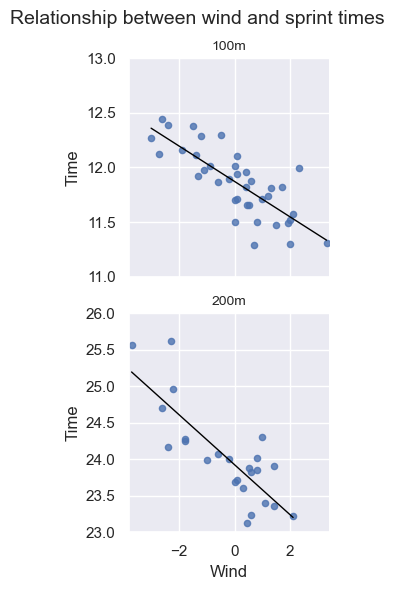

In [10]:
# set up empty graphs for each event
g = sns.FacetGrid(
    wind_events_valid,
    col='Event',
    col_wrap=1,
    sharey=False,
    sharex=True
)

# map regression line on to the graphs
g.map_dataframe(sns.regplot, x='Wind', y='Time',
                scatter_kws={'s': 20}, line_kws={'color': 'black', 'linewidth': 1}, ci = None)

#seting value limits for x and y for each event and changing figure names
for ax in g.axes.flat:
    event = ax.get_title().replace('Event =', '').strip()
    ax.set_title(event, fontsize = 10)

    #x axis set to min and max wind
    ax.set_xlim(wind_events_valid['Wind'].min() - 0.1, wind_events_valid['Wind'].max() + 0.1)

    #set y axis
    ax.yaxis.set_major_locator(MultipleLocator(0.5))

    if event == '100m':
        ax.set_ylim(11, 13)
    elif event == '200m':
        ax.set_ylim(23, 26)

#making graph title and showing result
g.fig.suptitle('Relationship between wind and sprint times', fontsize=14)
g.fig.subplots_adjust(top = 0.90)

plt.show()

# 3) Predict time from unseen/extreme wind values
### 100m only

In [11]:
sprint_100m = sprints[sprints['Event'] == '100m']

In [12]:
# Create OLS variable (ordinary least squares), with Wind as explanitary variable and Time as response
wind_vs_time = ols('Time~Wind', data=sprint_100m).fit()

In [13]:
# add explanatory data including extreme wind from -6 to 6
explanatory_data = pd.DataFrame({'Wind': np.arange(-6, 6.1)})

In [14]:
# predict time from these wind values
prediction_data = explanatory_data.assign(Time= wind_vs_time.predict(explanatory_data))

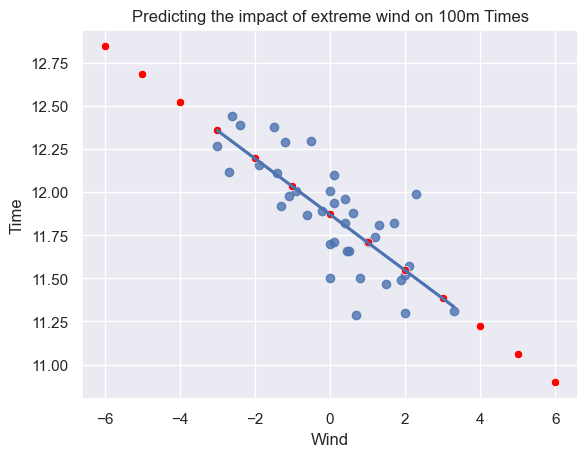

In [15]:
# print the result
sns.set_theme(style = 'darkgrid')
fig = plt.figure()

# creating the scatterplot graphs including the extreme wind values, with regression lines
sns.regplot(x='Wind', y='Time', data=sprint_100m, ci=None)
sns.scatterplot(x='Wind', y='Time', data=prediction_data, color='red')

#create title and show the plot
plt.title('Predicting the impact of extreme wind on 100m Times')
plt.show()

In [ ]:
# Note: Wind readings of +-6 are far outside the data range. These are expected values, but results may change when entries with a wider range of wind
# readings are added.

# 4) Assessing the fit of the wind vs time models

In [16]:
print(wind_vs_time.summary())

                            OLS Regression Results                            
Dep. Variable:                   Time   R-squared:                       0.618
Model:                            OLS   Adj. R-squared:                  0.608
Method:                 Least Squares   F-statistic:                     58.30
Date:                Mon, 02 Nov 2026   Prob (F-statistic):           4.90e-09
Time:                        15:16:48   Log-Likelihood:                 8.7918
No. Observations:                  38   AIC:                            -13.58
Df Residuals:                      36   BIC:                            -10.31
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept     11.8711      0.032    370.425      0.0

In [17]:
# get the RSE (residual standard error), to see difference between observed and expecetd sprint times based on wind
rse = np.sqrt(wind_vs_time.mse_resid)
print(rse)

0.19725279859146821


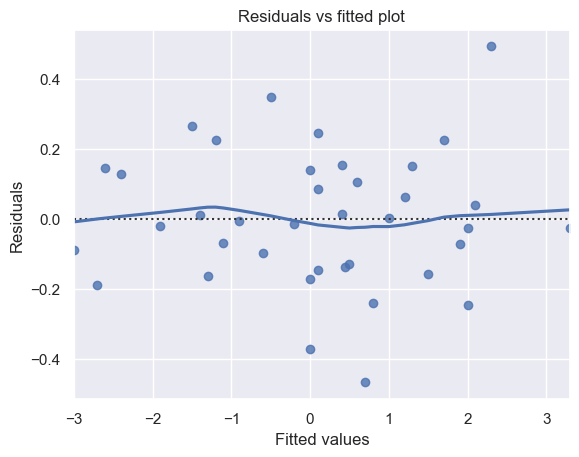

In [18]:
# residuals vs fitted plot
sns.residplot(x='Wind', y='Time', data = sprint_100m, lowess = True)
plt.xlabel('Fitted values')
plt.ylabel('Residuals')
plt.title('Residuals vs fitted plot')
plt.show()

In [19]:
# This residuals plot combined with the following QQ and scale location plot can be used to check your data is suitable for regression models

In [20]:
# Q-Q plot
from statsmodels.api import qqplot

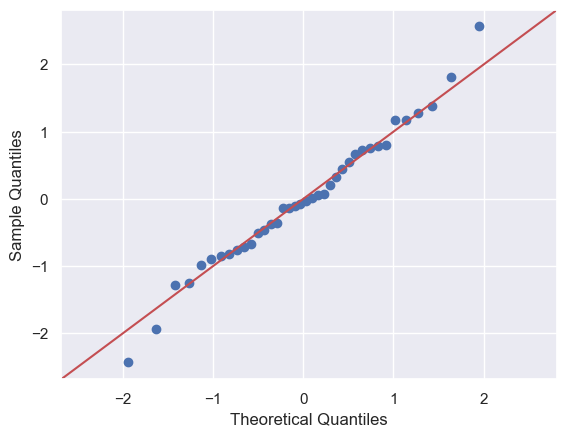

In [21]:
qqplot(data= wind_vs_time.resid, fit = True, line = '45')
plt.show()

In [22]:
# scale location plot
norm_residuals = wind_vs_time.get_influence().resid_studentized_internal

In [23]:
norm_residuals_sqrt = np.sqrt(np.abs(norm_residuals))

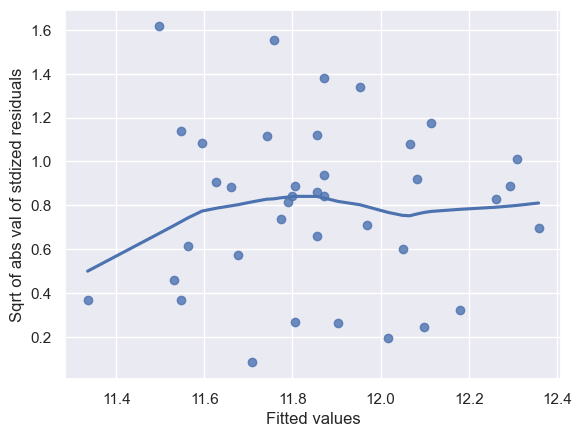

In [24]:
sns.regplot(x=wind_vs_time.fittedvalues, y=norm_residuals_sqrt, ci=None, lowess= True)
plt.xlabel('Fitted values')
plt.ylabel('Sqrt of abs val of stdized residuals')
plt.show()

### Looking at the impact of outliers

In [25]:
# first create a sprint 100m with no na wind rows, so that wind_vs_time and sprint100m lengths match
sprint_100m_wind = sprint_100m.dropna(subset='Wind').copy()

In [26]:
sum_data =wind_vs_time.get_influence().summary_frame()

In [27]:
# looking at leverage
sprint_100m_wind.loc[:, 'leverage'] = sum_data['hat_diag'].values
print(sprint_100m_wind.sort_values(by ='leverage', ascending = False))

         Date Event   Time  Location  Wind            Competition_type  \
89 2016-05-25  100m  11.31  Track 90  3.30                        Open   
28 2013-05-13  100m  12.27  Track 29 -3.00  County Championships Final   
29 2013-05-13  100m  12.12  Track 30 -2.70  County Championships Heats   
2  2000-09-20  100m  12.44   Track 3 -2.60                        Open   
43 2014-04-27  100m  12.39  Track 44 -2.40                        Open   
76 2015-06-25  100m  11.99  Track 77  2.30                        Open   
90 2016-05-25  100m  11.57  Track 91  2.10                        Open   
48 2014-07-14  100m  12.16  Track 49 -1.90                  Club match   
0  2000-09-13  100m  11.52   Track 1  2.00                        Open   
95 2016-08-31  100m  11.30  Track 96  2.00                        Open   
68 2015-04-27  100m  11.49  Track 69  1.90                        Open   
18 2012-08-13  100m  11.82  Track 19  1.70                  Club match   
85 2016-05-10  100m  12.38  Track 86 -

In [28]:
# cooks distance to see how outliers impact the model
sprint_100m_wind.loc[:, 'Cooks_dist'] = sum_data['cooks_d'].values

In [29]:
print(sprint_100m_wind.sort_values(by = 'Cooks_dist', ascending = False))

         Date Event   Time  Location  Wind            Competition_type  \
76 2015-06-25  100m  11.99  Track 77  2.30                        Open   
50 2014-08-11  100m  11.29  Track 51  0.70                      League   
29 2013-05-13  100m  12.12  Track 30 -2.70  County Championships Heats   
95 2016-08-31  100m  11.30  Track 96  2.00                        Open   
85 2016-05-10  100m  12.38  Track 86 -1.50  County Championships Final   
21 2012-09-05  100m  12.30  Track 22 -0.50                        Open   
56 2014-09-07  100m  11.50  Track 57  0.00                  Club match   
18 2012-08-13  100m  11.82  Track 19  1.70                  Club match   
2  2000-09-20  100m  12.44   Track 3 -2.60                        Open   
27 2013-05-03  100m  12.29  Track 28 -1.20                        Open   
84 2015-09-14  100m  11.50  Track 85  0.80                      League   
43 2014-04-27  100m  12.39  Track 44 -2.40                        Open   
34 2013-09-05  100m  12.10  Track 35  

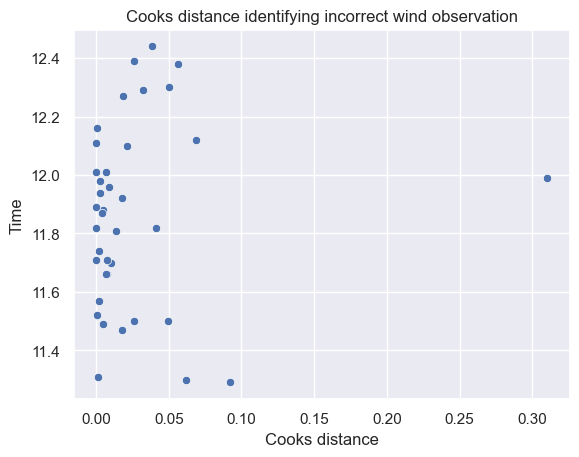

In [31]:
sns.scatterplot(x='Cooks_dist', y='Time', data = sprint_100m_wind)
plt.xlabel('Cooks distance')
plt.ylabel('Time')
plt.title('Cooks distance identifying incorrect wind observation')
plt.show()

# 5) Finding which numeric feature best predicts time in 100m

In [32]:
sprint_100m.info()

<class 'pandas.core.frame.DataFrame'>
Index: 44 entries, 0 to 96
Data columns (total 9 columns):
 #   Column                     Non-Null Count  Dtype         
---  ------                     --------------  -----         
 0   Date                       44 non-null     datetime64[ns]
 1   Event                      44 non-null     object        
 2   Time                       44 non-null     float64       
 3   Location                   44 non-null     object        
 4   Wind                       38 non-null     float64       
 5   Competition_type           44 non-null     object        
 6   Mean_time_of_other_racers  44 non-null     float64       
 7   Position                   44 non-null     int64         
 8   Podium                     44 non-null     object        
dtypes: datetime64[ns](1), float64(3), int64(1), object(4)
memory usage: 3.4+ KB


In [33]:
# creating an empty list to store the models
models = []

In [34]:
# creating df that only contains numeric features being used for predictions, and dropping response variable (time)
numeric_features = sprint_100m.drop(columns = ['Date', 'Time', 'Event', 'Location', 'Competition_type', 'Podium']).columns
print(numeric_features)

Index(['Wind', 'Mean_time_of_other_racers', 'Position'], dtype='object')


In [35]:
# get a model result using logistic regression for each feature
for col in numeric_features:
    model_result = ols(f"Time ~ {col}", data=sprint_100m).fit()
    models.append({
        'Feature': col, 'R_squared': model_result.rsquared, 'P Value': model_result.f_pvalue
    })

In [36]:
models_df = pd.DataFrame(models)
print(models_df)

                     Feature  R_squared       P Value
0                       Wind   0.618240  4.904841e-09
1  Mean_time_of_other_racers   0.146145  1.043984e-02
2                   Position   0.002737  7.358920e-01


In [37]:
# this will show which numeric variable is the strongest predictor for sprint time. Will most likely be wind time